# **FLUXO DE MODELAGEM DE CLASSIFICAÇÃO MULTINOMIAL**
### **COM VALIDAÇÃO ESTRATIFICADA SIMPLES + CRUZADA E SUBAMOSTRAGEM (BASE DESBALANCEADA)**
### *Case: Operadora de Saúde*
---



### **Bibliotecas**

In [1]:
# Instalação de bibliotecas não disponíveis na instalação padrão do Python no Google Colab
# ! pip install shap

In [4]:
import pandas as pd                                                                # Manipulação de dados
import numpy as np                                                                 # Realização de cálculos específicos
import matplotlib.pyplot as plt                                                    # Visualização de dados 
import seaborn as sns                                                              # Visualização de dados
import time                                                                        # Cálculo de tempo de execução
import math                                                                        # Funções matemáticas
from scipy.stats import randint, uniform, loguniform                               # Geração de valores aleatórios
from sklearn.compose import ColumnTransformer                                      # Transformação de colunas
from sklearn.preprocessing import StandardScaler, OneHotEncoder                    # Transformação de colunas
from sklearn.base import clone                                                     # Criação de cópias de modelos
from sklearn.model_selection import train_test_split                               # Validação simples
from imblearn.under_sampling import RandomUnderSampler                             # Subamostragem
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV            # Validação cruzada e estratificação de folds
from sklearn.utils.class_weight import compute_sample_weight                       # Cálculo de pesos para observações
from sklearn.linear_model import SGDClassifier                                     # Regressão logística com regularização
from sklearn.tree import DecisionTreeClassifier                                    # Árvore de decisão
from sklearn.ensemble import RandomForestClassifier                                # Floresta aleatória
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier        # Impulsionamento tradicional
from sklearn.ensemble import HistGradientBoostingClassifier                        # Impulsionamento com histogramas
from xgboost import XGBClassifier                                                  # Impulsionamento via XGBoost
from lightgbm import LGBMClassifier                                                # Impulsionamento via LightGBM
from sklearn.calibration import CalibratedClassifierCV                             # Calibração de probabilidades
from sklearn.calibration import calibration_curve                                  # Gráfico de curva de calibração
from sklearn.metrics import brier_score_loss                                       # Score de Brier
from sklearn.preprocessing import label_binarize                                   # Binarização da resposta (Score de Brier one-vs-rest)
from sklearn.metrics import confusion_matrix                                       # Análise de desempenho: matriz de classificação
from sklearn.metrics import accuracy_score, balanced_accuracy_score                # Análise de desempenho: acurácia e acurácia balanceada
from sklearn.metrics import get_scorer, auc, roc_auc_score, roc_curve              # Análise de desempenho: KS e AUC
from sklearn.inspection import permutation_importance                              # Importância de variáveis por permutação
import shap                                                                        # Interpretabilidade de variáveis nos modelos

### **Leitura da base de dados**

In [5]:
dados = pd.read_table("Operadora_Saude.txt",
                      sep="\t",
                      decimal=".",
                      header=0)

### **Visualização da base de dados**

In [6]:
dados.head()

,ID_CLIENTE,NIVEL_SATISFACAO,RELACAO_CUSTO_RENDA,QTDE_UTILIZACOES_12M,TEMPO_PLANO,QTDE_SERVICOS_12M,QTDE_ATRASOS_12M,FLAG_MUDANCA_RESID_12M,QTDE_RECLAMACOES_12M,QTDE_DEPENDENTES,IDADE,STATUS
0,CLI000001,7.7,0.11,6,4.4,3,0,Nao,0,2,78,Mantem
1,CLI000002,9.8,0.49,3,3.3,1,0,Nao,0,1,21,Mantem
2,CLI000003,6.2,0.12,4,6.4,1,0,Nao,0,0,1,Up
3,CLI000004,7.4,0.35,15,5.6,1,2,Nao,3,0,10,Mantem
4,CLI000005,0.3,0.25,26,3.5,2,2,Nao,0,1,89,Up


### **Dimensões da base de dados**

In [7]:
dados.shape

(100000, 12)

### **Tipos das colunas da base de dados**

In [8]:
dados.dtypes

ID_CLIENTE                 object
NIVEL_SATISFACAO          float64
RELACAO_CUSTO_RENDA       float64
QTDE_UTILIZACOES_12M        int64
TEMPO_PLANO               float64
QTDE_SERVICOS_12M           int64
QTDE_ATRASOS_12M            int64
FLAG_MUDANCA_RESID_12M     object
QTDE_RECLAMACOES_12M        int64
QTDE_DEPENDENTES            int64
IDADE                       int64
STATUS                     object
dtype: object

### **Etapa 1: Especificação de variáveis e análise bivariada**

*Lista de nomes das variáveis explicativas, separando em quantitativas e qualitativas*

In [9]:
# Variáveis explicativas quantitativas (deixar vazio [] caso não haja nenhuma)
lista_X_quanti = [
    'NIVEL_SATISFACAO',
    'RELACAO_CUSTO_RENDA',
    'QTDE_UTILIZACOES_12M',
    'TEMPO_PLANO',
    'QTDE_SERVICOS_12M',
    'QTDE_ATRASOS_12M',
    'QTDE_RECLAMACOES_12M',
    'QTDE_DEPENDENTES',
    'IDADE',
]

# Variáveis explicativas qualitativas (deixar vazio [] caso não haja nenhuma)
lista_X_quali = [
    'FLAG_MUDANCA_RESID_12M'
]

*Objetos para variável resposta (y) e explicativas (X)*

In [10]:
y = dados['STATUS']
X = dados[lista_X_quali + lista_X_quanti]

*Análise univariada: variável resposta*

In [ ]:
y.value_counts()

STATUS
Mantem       67000
Up           13000
Down         10000
CancInvol     6000
CancVol       4000
Name: count, dtype: int64

In [12]:
y.value_counts(normalize=True)

STATUS
Mantem       0.67
Up           0.13
Down         0.10
CancInvol    0.06
CancVol      0.04
Name: proportion, dtype: float64

In [13]:
# Ordenando as categorias da resposta y
ordem_categorias = ["CancInvol", "CancVol", "Down", "Mantem", "Up"]
y = y.astype(pd.CategoricalDtype(categories=ordem_categorias, ordered=True))

*Análise bivariada: gráficos de boxplot para variáveis explicativas quantitativas versus variável resposta*

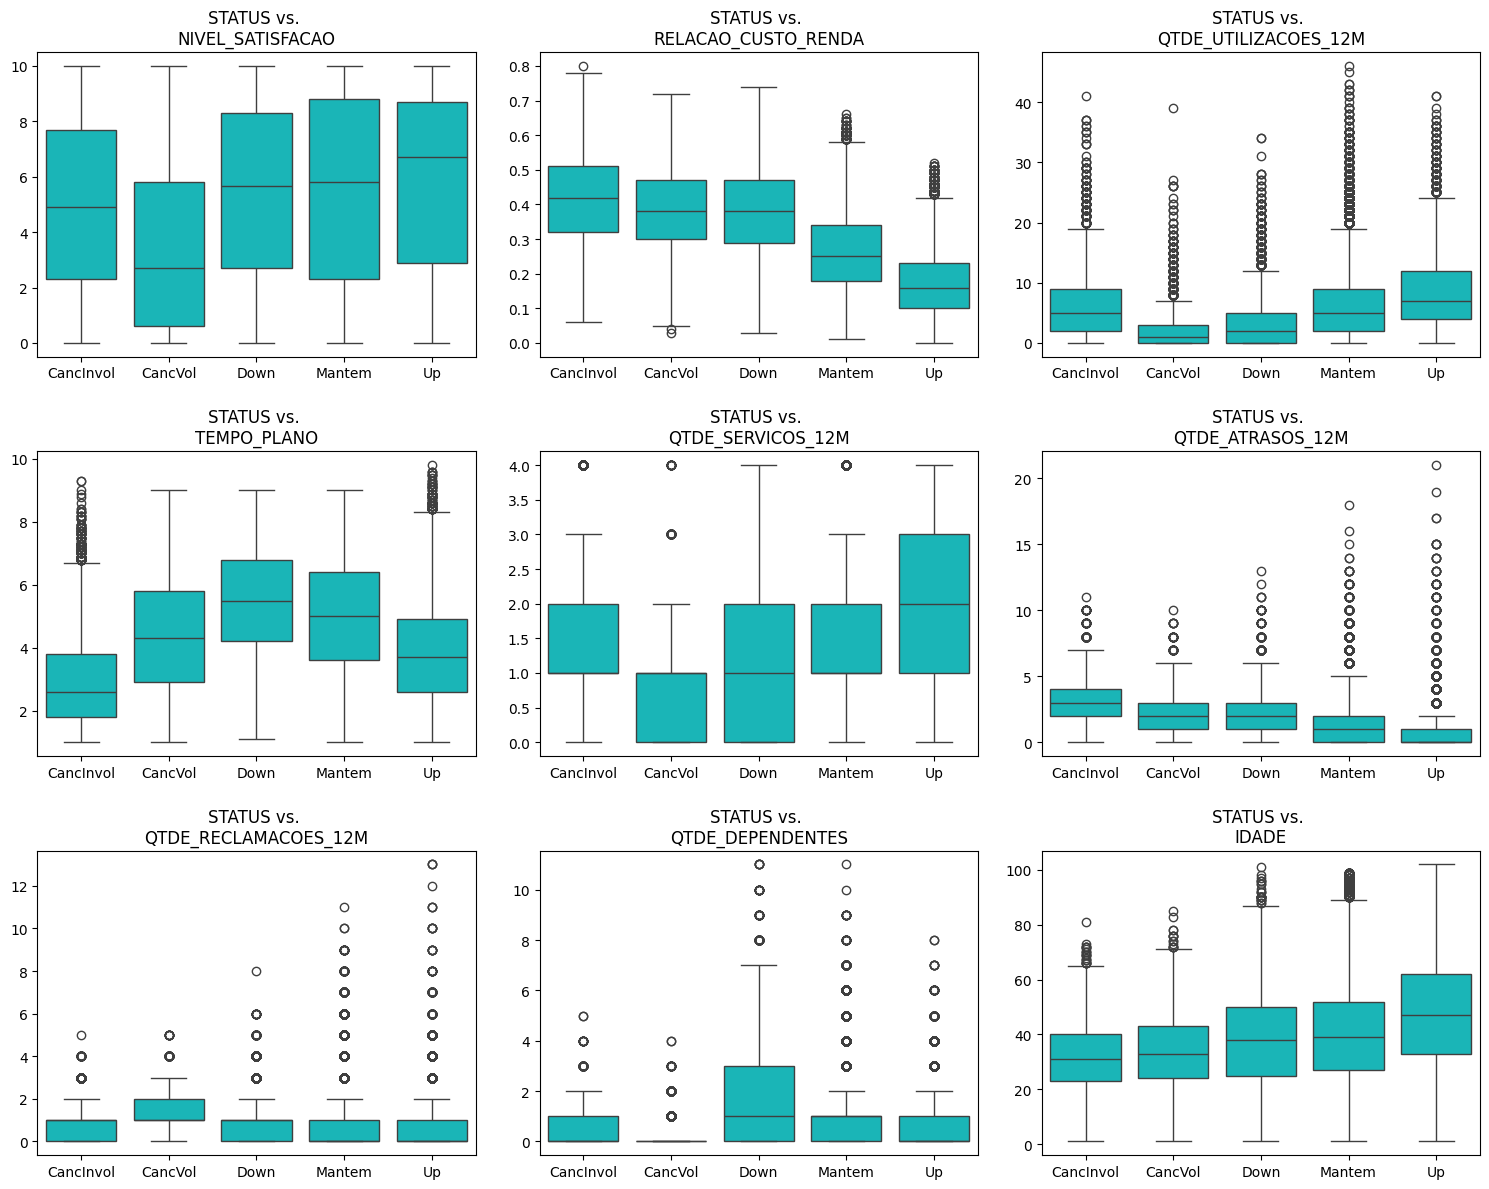

In [14]:
if lista_X_quanti:
    n = len(lista_X_quanti)
    ncols = 3
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows=nrows,
                             ncols=ncols,
                             figsize=(5 * ncols, 4 * nrows))
    axes = axes.flatten()

    for i, var in enumerate(lista_X_quanti):
        sns.boxplot(y=dados[var],
                    x=y,
                    ax=axes[i],
                    color='darkturquoise')
        axes[i].set_title(f'{y.name} vs. \n{var}')
        axes[i].tick_params(axis='x', rotation=0)
        axes[i].set_xlabel("")
        axes[i].set_ylabel("")

    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

    fig.tight_layout(h_pad=2, w_pad=2)
    plt.show()

*Análise bivariada: gráficos de barras empilhadas 100% para variáveis explicativas qualitativas versus variável resposta*

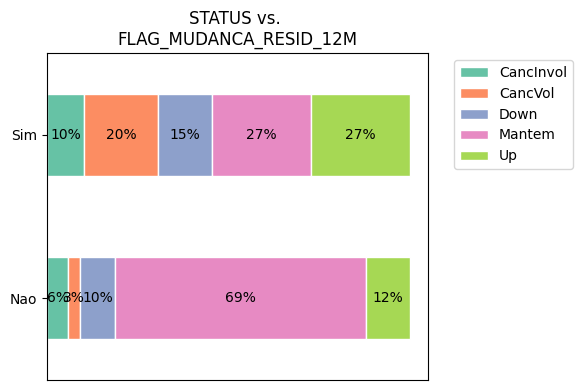

In [ ]:
    if lista_X_quali:
        n = len(lista_X_quali)
        ncols = 2
        nrows = math.ceil(n / ncols)
        fig, axes = plt.subplots(nrows=nrows,
                                ncols=ncols,
                                figsize=(5 * ncols, 4 * nrows))
        axes = axes.flatten()

        for i, var in enumerate(lista_X_quali):
            ct = pd.crosstab(dados[var], y, normalize='index')
            ct.plot(kind='barh',
                    stacked=True,
                    ax=axes[i],
                    color=sns.color_palette("Set2"),
                    edgecolor='white')
            axes[i].set_title(f'{y.name} vs. \n{var}')
            axes[i].tick_params(axis='x', rotation=0)
            axes[i].legend(bbox_to_anchor=(1.05, 1), loc='upper left')
            axes[i].set_xticks([])
            axes[i].set_ylabel("")
            for container in axes[i].containers:
                axes[i].bar_label(container,
                                labels=[f"{w.get_width()*100:.0f}%" for w in container],
                                label_type='center')
            if i != 0:
                axes[i].legend_.remove()  # Manter legenda apenas no primeiro gráfico

        for j in range(i+1, len(axes)):
            fig.delaxes(axes[j])

        fig.tight_layout(h_pad=2, w_pad=2)
        plt.show()

### **Etapa 2: Divisão de treino e teste externo**

*Divisão inicial*

In [16]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y,
                                                        test_size=0.2,
                                                        stratify=y,
                                                        random_state=123)

*Representação das categorias de y como números (requerido por alguns algoritmos e para calibração)*

In [17]:
y_treino = y_treino.astype(pd.CategoricalDtype(categories=ordem_categorias, ordered=True)).cat.codes.rename(y.name)
y_teste = y_teste.astype(pd.CategoricalDtype(categories=ordem_categorias, ordered=True)).cat.codes.rename(y.name)

In [18]:
y_treino.value_counts()

STATUS
3    53600
4    10400
2     8000
0     4800
1     3200
Name: count, dtype: int64

***(Se necessário)*** *Sub-amostragem no conjunto de treino*

In [19]:
X_treino_inicial = X_treino.copy()   # Cópias dos objetos originais
y_treino_inicial = y_treino.copy()

tamanho_classes = {                  # Altere os tamanhos das classes
    0: 2000,
    1: 2000,
    2: 2000,
    3: 2000,
    4: 2000
}
subamostragem = RandomUnderSampler(sampling_strategy=tamanho_classes, random_state=123)
X_treino, y_treino = subamostragem.fit_resample(X_treino, y_treino)

In [20]:
y_treino.value_counts()

STATUS
0    2000
1    2000
2    2000
3    2000
4    2000
Name: count, dtype: int64

### **Etapa 3: Pré-processamento de variáveis explicativas**

*Definição das funções de pré-processamento: Padronização das variáveis quantitativas + Codificação one-hot para variáveis qualitativas*

In [21]:
preprocessador = ColumnTransformer(transformers=[
    ("quanti", StandardScaler(), lista_X_quanti),
    ("quali", OneHotEncoder(sparse_output=False, drop="first", handle_unknown='ignore'), lista_X_quali)
],
    remainder="passthrough"
)

*Criação do pré-processamento no conjunto de treino* <br>

In [22]:
X_treino_tratada = preprocessador.fit_transform(X_treino)  # O pré-processamento não deve envolver o conjunto de teste externo, que deve ficar reservado apenas para aplicações de resultados já obtidos, e nunca construções
if lista_X_quali:
    nomes_quali = list(preprocessador.named_transformers_['quali'].get_feature_names_out(lista_X_quali))
else:
    nomes_quali = []
nomes_variaveis = list(lista_X_quanti) + nomes_quali

In [23]:
X_treino_tratada = pd.DataFrame(X_treino_tratada, columns=nomes_variaveis)
X_treino_tratada.head()

,NIVEL_SATISFACAO,RELACAO_CUSTO_RENDA,QTDE_UTILIZACOES_12M,TEMPO_PLANO,QTDE_SERVICOS_12M,QTDE_ATRASOS_12M,QTDE_RECLAMACOES_12M,QTDE_DEPENDENTES,IDADE,FLAG_MUDANCA_RESID_12M_Sim
0,1.257633,-0.554590,3.403292,0.564732,1.497917,-0.511446,0.042479,0.158698,0.417623,0.0
1,-0.854071,-0.554590,0.278459,-0.749907,1.497917,0.028966,0.042479,-0.628494,-0.149538,0.0
2,-0.609236,1.318483,1.932782,-1.591276,-0.423968,1.650202,0.971993,0.945890,-0.659982,0.0
3,0.829171,1.251588,-0.456795,-1.223177,-0.423968,1.650202,0.971993,-0.628494,-1.000278,0.0
4,1.104611,-0.353904,1.013714,-0.855078,0.536975,2.190614,0.042479,-0.628494,-0.830130,0.0


*Aplicação do pré-processamento no conjunto de teste externo*

In [24]:
X_teste_tratada = preprocessador.transform(X_teste)  # Note que o mesmo objeto de pré-processamento deve ser utilizado, agora com 'transform' em vez de 'fit_transform'
X_teste_tratada = pd.DataFrame(X_teste_tratada, columns=nomes_variaveis)
X_teste_tratada.head()

,NIVEL_SATISFACAO,RELACAO_CUSTO_RENDA,QTDE_UTILIZACOES_12M,TEMPO_PLANO,QTDE_SERVICOS_12M,QTDE_ATRASOS_12M,QTDE_RECLAMACOES_12M,QTDE_DEPENDENTES,IDADE,FLAG_MUDANCA_RESID_12M_Sim
0,0.645545,-0.688381,1.197528,0.617318,0.536975,-0.511446,0.042479,-0.628494,-1.397291,0.0
1,-1.221324,-0.353904,1.932782,-1.486105,1.497917,-1.051858,-0.887036,0.158698,-0.036105,0.0
2,1.410655,-0.955963,0.278459,0.564732,-0.423968,1.109790,0.971993,0.158698,-0.943562,0.0
3,-0.150170,-0.554590,-1.008236,0.038877,-1.384910,-0.511446,-0.887036,1.733083,0.984784,0.0
4,1.441259,-1.758709,0.278459,-0.434394,0.536975,-0.511446,0.042479,-0.628494,0.474339,0.0


### **Etapa 4: Definição do algoritmo e intervalos de busca de hiperparâmetros**

In [25]:
algoritmos = {

    'REGRESSÃO LOGÍSTICA REGULARIZADA': (SGDClassifier(random_state=123, loss='log_loss', max_iter=10000, tol=1e-3), {
        'penalty': ['l2', 'l1', 'elasticnet'],
        'alpha': loguniform(1e-5, 1e1),               # Peso da penalização
        'l1_ratio': uniform(0, 1),                    # Contribuição da penalização LASSO (L1) em relação a Ridge (L2)
        'eta0': loguniform(1e-4, 1e-1),               # Taxa de aprendizado inicial
        'learning_rate': ['constant',                 # Atualização de eta0: manter sempre constante
                          'invscaling',               # Atualização de eta0: reduzir gradativamente ao longo das iterações
                          'adaptive']                 # Atualização de eta0: reduzir gradativamente ao longo das iterações, se não houver redução do erro
    }),

    'ÁRVORE DE DECISÃO': (DecisionTreeClassifier(random_state=123), {
        'criterion': ['gini', 'entropy'],             # Critério de impureza
        'min_impurity_decrease': uniform(0, 0.05),    # Valor mínimo de redução de impureza
        'min_samples_split': randint(1000, 5001),     # Qtde. mínima de observações no nó "pai" (ATENÇÃO: depende do tamanho da base)
        'min_samples_leaf': randint(500, 1001),       # Qtde. mínima de observações no nó "filho" (ATENÇÃO: depende do tamanho da base)
        'max_depth': randint(2, 11)                   # Profundidade máxima da árvore
    }),

    'FLORESTA ALEATÓRIA': (RandomForestClassifier(random_state=123, n_jobs = -1), {
        'n_estimators': randint(10, 301),             # Qtde. de árvores na floresta
        'min_impurity_decrease': uniform(0, 0.05),    # Valor mínimo de redução de impureza
        'min_samples_split': randint(1000, 5001),     # Qtde. mínima de observações no nó "pai" (ATENÇÃO: depende do tamanho da base)
        'min_samples_leaf': randint(500, 1001),       # Qtde. mínima de observações no nó "filho" (ATENÇÃO: depende do tamanho da base)
        'max_samples': uniform(0.6, 0.4),             # Percentual de observações consideradas em cada árvore
        'max_features': ['sqrt', 'log2', None],       # Qtde. de variáveis consideradas em cada árvore
        'max_depth': randint(2, 11)                   # Profundidade máxima das árvores
    }),

    'ADABOOST': (AdaBoostClassifier(random_state=123), {
        'n_estimators': randint(10, 301),             # Qtde. de árvores no boosting
        'learning_rate': loguniform(1e-4, 1e-1)       # Taxa de aprendizado
    }),

    'GRADIENT BOOSTING': (GradientBoostingClassifier(random_state=123), {
        'n_estimators': randint(10, 301),             # Qtde. de árvores no boosting
        'min_impurity_decrease': uniform(0, 0.05),    # Valor mínimo de redução de impureza
        'learning_rate': loguniform(1e-4, 1e-1),      # Taxa de aprendizado
        'min_samples_split': randint(1000, 5001),     # Qtde. mínima de observações no nó "pai" (ATENÇÃO: depende do tamanho da base)
        'min_samples_leaf': randint(500, 1001),       # Qtde. mínima de observações no nó "filho" (ATENÇÃO: depende do tamanho da base)
        'subsample': uniform(0.6, 0.4),               # Percentual de observações consideradas em cada árvore
        'max_features': ['sqrt', 'log2', None],       # Qtde. de variáveis consideradas em cada árvore
        'max_depth': randint(2, 11)                   # Profundidade máxima das árvores
    }),

    'GRADIENT BOOSTING COM HISTOGRAMAS': (HistGradientBoostingClassifier(random_state=123), {
        'max_iter': randint(10, 301),                 # Qtde. de árvores no boosting
        'learning_rate': loguniform(1e-4, 1e-1),      # Taxa de aprendizado
        'min_samples_leaf': randint(500, 1001),       # Qtde. mínima de observações no nó "filho" (ATENÇÃO: depende do tamanho da base)
        'max_leaf_nodes': randint(10, 31),            # Qtde. máxima de nós finais (ATENÇÃO: depende do tamanho da base)
        'max_bins': randint(10, 255),                 # Qtde. máxima de bins para discretização
        'l2_regularization': loguniform(1e-5, 1e2),   # Contribuição da penalização Ridge (L2)
        'max_depth': randint(2, 11)                   # Profundidade máxima das árvores
    }),

    'XGBOOST': (XGBClassifier(random_state=123, n_jobs=-1), {
        'n_estimators': randint(10, 301),             # Qtde. de árvores no boosting
        'learning_rate': loguniform(1e-4, 1e-1),      # Taxa de aprendizado
        'colsample_bytree': uniform(0.5, 0.5),        # Percentual de variáveis consideradas em cada árvore
        'subsample': uniform(0.6, 0.4),               # Percentual de observações consideradas em cada árvore
        'gamma': uniform(0, 5),                       # Redução mínima na função de perda para realizar uma quebra
        'reg_alpha': loguniform(1e-5, 1e2),           # Contribuição da penalização LASSO (L1)
        'reg_lambda': loguniform(1e-5, 1e2),          # Contribuição da penalização Ridge (L2)
        'max_depth': randint(2, 11)                   # Profundidade máxima das árvores
    }),

    'LIGHTGBM': (LGBMClassifier(random_state=123, n_jobs=-1, verbosity=-1), {
        'n_estimators': randint(10, 301),             # Qtde. de árvores no boosting
        'learning_rate': loguniform(1e-4, 1e-1),      # Taxa de aprendizado
        'min_child_samples': randint(500, 1001),      # Qtde. mínima de observações no nó "filho" (ATENÇÃO: depende do tamanho da base)
        'num_leaves': randint(10, 31),                # Qtde. máxima de nós finais (ATENÇÃO: depende do tamanho da base)
        'subsample': uniform(0.6, 0.4),               # Percentual de observações consideradas em cada árvore
        'reg_alpha': loguniform(1e-5, 1e2),           # Contribuição da penalização LASSO (L1)
        'reg_lambda': loguniform(1e-5, 1e2),          # Contribuição da penalização Ridge (L2)
        'max_depth': randint(2, 11)                   # Profundidade máxima das árvores
    })
    
}

### **Etapa 5: Construção de modelos usando validação cruzada, busca aleatória e teste externo**

*Estratégia de validação cruzada estratificada (stratified k-fold) e quantidade máxima de iterações de busca*

In [26]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
qtd_iteracoes = 100

*Construção dos modelos*

In [27]:
resultados = []                                                              # Lista para armazenar resultados
contador_modelos = 0                                                         # Contador de modelos testados
pesos_treino = compute_sample_weight(class_weight='balanced', y=y_treino)    # Pesos das observações no treino (pois alguns algoritmos não aceitam o argumento 'class_weight')

for nome_algoritmo, (classe_algoritmo, hiperparametros) in algoritmos.items():

    # Início da contagem de tempo e de modelos
    inicio = time.time()

    # Busca aleatória de hiperparâmetros com validação cruzada (randomized search)
    busca = RandomizedSearchCV(
        estimator=classe_algoritmo,
        param_distributions=hiperparametros,
        n_iter=1 if not hiperparametros else qtd_iteracoes,
        scoring='roc_auc_ovr',
        cv=kf,
        return_train_score=True,
        random_state=123,
        n_jobs=-1
    )

    # Ajuste dos modelos
    busca.fit(X_treino_tratada, y_treino, sample_weight=pesos_treino)

    # Armazenar os resultados da busca
    resultados_aux = pd.DataFrame({
        "num_modelo": [f"Modelo {contador_modelos + i}" for i in range(len(busca.cv_results_["params"]))],
        "nome_algoritmo": nome_algoritmo,
        "classe_algoritmo": type(classe_algoritmo).__name__,
        "hiperparametros": busca.cv_results_["params"],
        "media_score_treino": busca.cv_results_["mean_train_score"],
        "media_score_teste_interno": busca.cv_results_["mean_test_score"],
        "dp_score_treino": busca.cv_results_["std_train_score"],
        "dp_score_teste_interno": busca.cv_results_["std_test_score"]
    })

    metrica = "roc_auc_ovr"
    scorer = get_scorer(metrica)

    # Calcular score no teste externo, para cada modelo
    score_teste = []
    for params in resultados_aux["hiperparametros"]:
        estimador = busca.best_estimator_
        p_hat_teste = estimador.predict_proba(X_teste_tratada)[:, 1]
        score = scorer(estimador, X_teste_tratada, y_teste)
        score_teste.append(score)

    # Adicionar coluna de score em teste externo e colunas de variações absolutas de score em relação ao treino
    resultados_aux["score_teste_externo"] = score_teste
    resultados_aux["var_abs_media_score_teste_interno"] = abs(resultados_aux["media_score_teste_interno"] - resultados_aux["media_score_treino"])
    resultados_aux["var_abs_score_teste_externo"] = abs(resultados_aux["score_teste_externo"] - resultados_aux["media_score_treino"])

    resultados.append(resultados_aux)
    contador_modelos += len(resultados_aux)

    # Fim da contagem de tempo e mensagem de finalização
    fim = time.time()
    print(f"({math.ceil(contador_modelos/qtd_iteracoes)} de {len(algoritmos)}) Processo concluído para o algoritmo {nome_algoritmo} em {fim - inicio:.1f} segundos!")

# Criação de data frame com os resultados
resultados = pd.concat(resultados, ignore_index=True)

(1 de 8) Processo concluído para o algoritmo REGRESSÃO LOGÍSTICA REGULARIZADA em 75.7 segundos!
(2 de 8) Processo concluído para o algoritmo ÁRVORE DE DECISÃO em 36.2 segundos!
(3 de 8) Processo concluído para o algoritmo FLORESTA ALEATÓRIA em 155.9 segundos!
(4 de 8) Processo concluído para o algoritmo ADABOOST em 358.1 segundos!
(5 de 8) Processo concluído para o algoritmo GRADIENT BOOSTING em 470.3 segundos!
(6 de 8) Processo concluído para o algoritmo GRADIENT BOOSTING COM HISTOGRAMAS em 290.2 segundos!
(7 de 8) Processo concluído para o algoritmo XGBOOST em 193.6 segundos!
(8 de 8) Processo concluído para o algoritmo LIGHTGBM em 329.5 segundos!


### **Etapa 6: Comparação de modelos**

*Ordenação dos melhores modelos*

In [28]:
# Escolha por qual coluna ordenar
ordenar_por = "media_score_teste_interno"
# ordenar_por = "score_teste_externo"

# Escolha quais o percentuais máximos de variação de score (da média do treino para a média do teste interno; e da média do treino para o teste externo)
max_var_perc_score_teste_interno = 0.1  # ex.: 0.1 representa 10%
max_var_perc_score_teste_externo = 0.1

# Ordenação e filtragem
resultados_filt_ord = resultados[(resultados['var_abs_media_score_teste_interno'] < max_var_perc_score_teste_interno) & (resultados['var_abs_score_teste_externo'] < max_var_perc_score_teste_externo)]
resultados_filt_ord = resultados_filt_ord.sort_values(ordenar_por, ascending=False)

*Exibição dos melhores modelos, em formato de tabela e gráfico*

In [29]:
pd.set_option('display.float_format', '{:.3f}'.format)   # Quantidade de casas decimais
resultados_filt_ord[['num_modelo',
                     'nome_algoritmo',
                     'hiperparametros',
                     'media_score_treino',
                     'dp_score_treino',
                     'media_score_teste_interno',
                     'dp_score_teste_interno',
                     'var_abs_media_score_teste_interno',
                     'score_teste_externo',
                     'var_abs_score_teste_externo']].head(10)    # Escolha quantos modelos quer exibir

,num_modelo,nome_algoritmo,hiperparametros,media_score_treino,dp_score_treino,media_score_teste_interno,dp_score_teste_interno,var_abs_media_score_teste_interno,score_teste_externo,var_abs_score_teste_externo
652,Modelo 652,XGBOOST,"{'colsample_bytree': 0.5203415952456906, 'gamm...",0.940,0.001,0.908,0.004,0.032,0.880,0.059
658,Modelo 658,XGBOOST,"{'colsample_bytree': 0.5120742028918862, 'gamm...",0.928,0.001,0.907,0.004,0.022,0.880,0.048
660,Modelo 660,XGBOOST,"{'colsample_bytree': 0.6747592636959783, 'gamm...",0.932,0.001,0.906,0.004,0.026,0.880,0.052
685,Modelo 685,XGBOOST,"{'colsample_bytree': 0.807947307703502, 'gamma...",0.924,0.001,0.906,0.004,0.018,0.880,0.044
630,Modelo 630,XGBOOST,"{'colsample_bytree': 0.686259695522289, 'gamma...",0.936,0.001,0.906,0.005,0.030,0.880,0.055
637,Modelo 637,XGBOOST,"{'colsample_bytree': 0.7297984619802372, 'gamm...",0.921,0.001,0.905,0.004,0.015,0.880,0.040
633,Modelo 633,XGBOOST,"{'colsample_bytree': 0.7510355501633714, 'gamm...",0.950,0.000,0.904,0.004,0.046,0.880,0.070
401,Modelo 401,GRADIENT BOOSTING,"{'learning_rate': 0.08755734725056502, 'max_de...",0.915,0.001,0.904,0.004,0.011,0.879,0.036
494,Modelo 494,GRADIENT BOOSTING,"{'learning_rate': 0.06551888252203208, 'max_de...",0.924,0.001,0.904,0.004,0.020,0.879,0.045
641,Modelo 641,XGBOOST,"{'colsample_bytree': 0.7033894467369343, 'gamm...",0.930,0.001,0.904,0.005,0.027,0.880,0.050


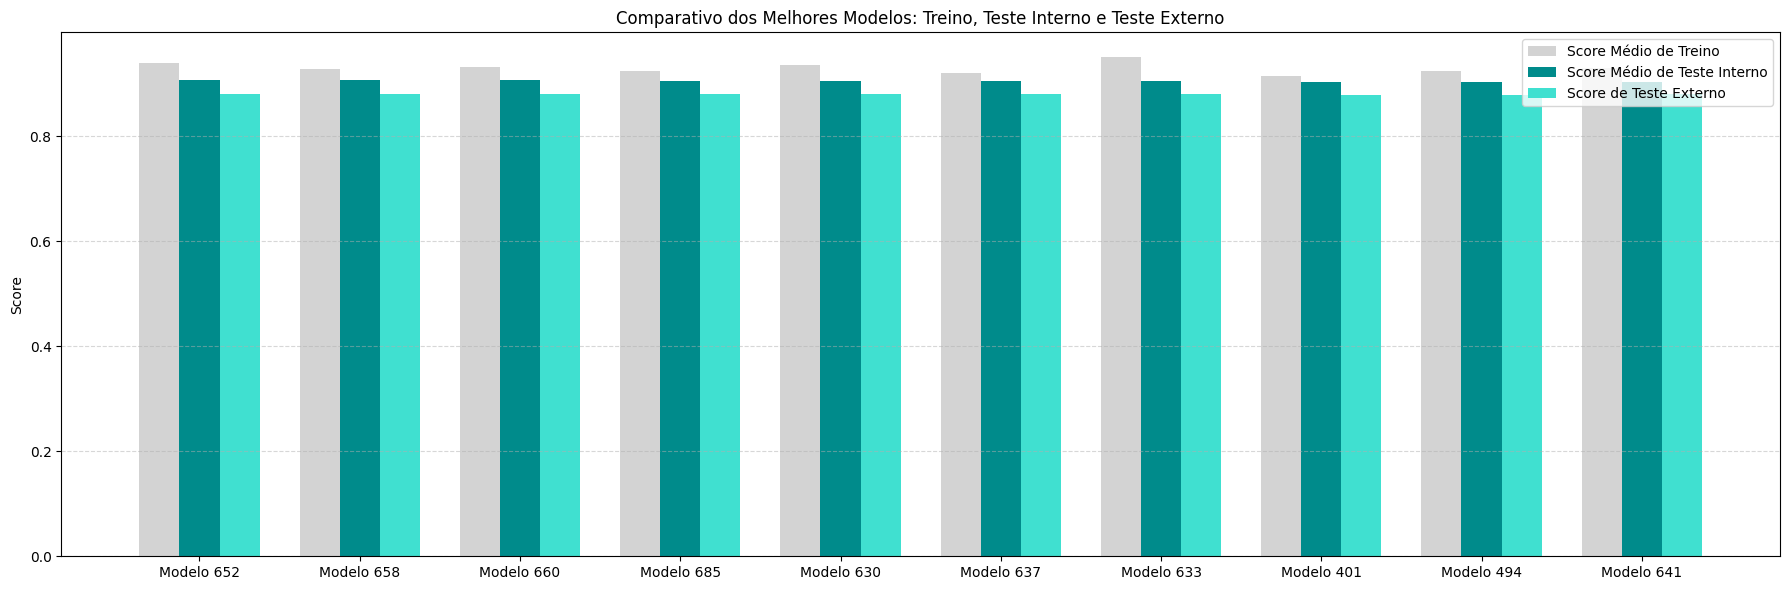

In [30]:
dados_grafico = resultados_filt_ord.head(10)     # Escolha quantos modelos quer exibir
x_pos = np.arange(len(dados_grafico))            # Posições dos rótulos do eixo X
largura_barra = 0.25                             # Largura das barras

plt.figure(figsize=(18, 6))
plt.bar(x_pos - largura_barra,                   # Série com score médio de treino
        dados_grafico["media_score_treino"],
        width=largura_barra,
        label="Score Médio de Treino",
        color="lightgray")
plt.bar(x_pos,                                   # Série com score médio de teste interno
        dados_grafico["media_score_teste_interno"],
        width=largura_barra,
        label="Score Médio de Teste Interno",
        color="darkcyan")
plt.bar(x_pos + largura_barra,                   # Série com score médio de teste externo
        dados_grafico["score_teste_externo"],
        width=largura_barra,
        label="Score de Teste Externo",
        color="turquoise")

plt.xticks(x_pos,
           dados_grafico["num_modelo"],
           rotation=0,
           ha='center')
plt.ylabel("Score")
plt.title("Comparativo dos Melhores Modelos: Treino, Teste Interno e Teste Externo")
plt.legend()
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

### **Etapa 7: Escolha do modelo**

*Escolha do modelo*

In [31]:
num_modelo_escolhido = "Modelo 652"

*Características do modelo escolhido*

In [32]:
linha = resultados.loc[resultados["num_modelo"] == num_modelo_escolhido].squeeze()
nome_algoritmo = linha["nome_algoritmo"]
hiperparametros = linha["hiperparametros"]
classe = algoritmos[nome_algoritmo][0]
print(f"O modelo final adotado foi construído com o algoritmo {nome_algoritmo}, com hiperparâmetros: { {k: round(v, 4) if isinstance(v, float) else v for k, v in hiperparametros.items()} }")

O modelo final adotado foi construído com o algoritmo XGBOOST, com hiperparâmetros: {'colsample_bytree': np.float64(0.5203), 'gamma': np.float64(1.6638), 'learning_rate': np.float64(0.0694), 'max_depth': 8, 'n_estimators': 263, 'reg_alpha': np.float64(0.0001), 'reg_lambda': np.float64(2.4593), 'subsample': np.float64(0.7877)}


*Retreino do modelo no conjunto de treino completo*

In [33]:
modelo_final = classe.set_params(**hiperparametros)
modelo_final.fit(X_treino_tratada, y_treino, sample_weight=pesos_treino)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=np.float64(0.5203415952456906), device=None,
              early_stopping_rounds=None, enable_categorical=False,
              eval_metric=None, feature_types=None, feature_weights=None,
              gamma=np.float64(1.6637680853097048), grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=np.float64(0.06939986405357666), max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=8, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=263, n_jobs=-1,
              num_parallel_tree=None, ...)

### **Etapa 8: Calibração e análises adicionais no conjunto de teste externo**

*Aplicação do modelo final no conjunto de teste externo*

In [34]:
p_hat_teste = modelo_final.predict_proba(X_teste_tratada)
classes = modelo_final.classes_

*Atribuição da categoria de resposta predita pelo modelo, com base na maior probabilidade*

In [35]:
y_hat_teste = classes[p_hat_teste.argmax(axis=1)]

*Verificação gráfica de calibração das probabilidades*

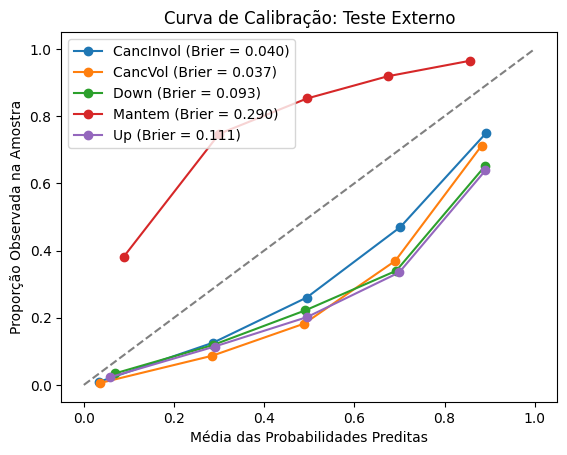

In [36]:
# Cálculos
y_one_hot = label_binarize(y_teste, classes=classes)

# Gráfico da curva de calibração para cada classe (one-versus-rest)
plt.plot([0,1],[0,1],'--', color='gray')
for k, cls in enumerate(classes):
    y_bin = (y_teste == cls).astype(int)
    prop_obs, p_hat_media = calibration_curve(y_bin, p_hat_teste[:, k])
    brier = brier_score_loss(y_bin, p_hat_teste[:, k])
    plt.plot(p_hat_media,
             prop_obs,
             'o-',
             label=f"{ordem_categorias[cls]} (Brier = {brier:.3f})")
plt.xlabel("Média das Probabilidades Preditas")
plt.ylabel("Proporção Observada na Amostra")
plt.title("Curva de Calibração: Teste Externo")
plt.legend()
plt.show()

***(Se necessário)*** *Atualização de probabilidades preditas no teste, por meio de recalibração das probabilidades no conjunto de treino*

In [37]:
# Recalibração do modelo no treino - escolha o método: 'isotonic' (n > 1000) ou 'sigmoid'
modelo_final_calibrado = CalibratedClassifierCV(modelo_final, method='isotonic', cv=5)
modelo_final_calibrado.fit(X_treino_tratada, y_treino)

# Armazenamento de probabilidades não calibradas e cálculo das probabilidades calibradas
p_hat_teste_nao_calibradas = p_hat_teste
p_hat_teste = modelo_final_calibrado.predict_proba(X_teste_tratada)

***(Em caso de subamostragem)*** *Correção de probabilidades preditas no teste, por conta de subamostragem*

In [38]:
# Cálculo de razões entre as proporções originais (antes da subamostragem) e das proporções novas (após subamostragem)
dist_y_pre_reamostragem = pd.Series(y_treino_inicial).value_counts(normalize=True).reindex(classes).to_numpy()
dist_y_pos_reamostragem = pd.Series(y_treino).value_counts(normalize=True).reindex(classes).to_numpy()
w = dist_y_pre_reamostragem / dist_y_pos_reamostragem

# Armazenamento de probabilidades calibradas e cálculo das probabilidades calibradas + corrigidas após subamostragem
p_hat_teste_calibradas = p_hat_teste
p_hat_teste = p_hat_teste * w
p_hat_teste = p_hat_teste / p_hat_teste.sum(axis=1, keepdims=True)

***(Se necessário)*** *Verificação gráfica de calibração das probabilidades - atualização pós calibração*

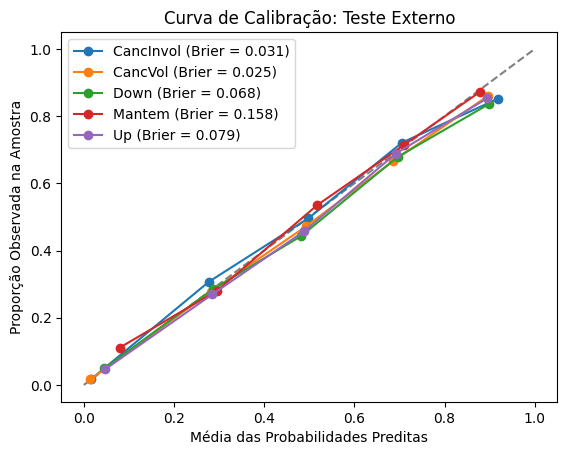

In [39]:
# Cálculos
y_one_hot = label_binarize(y_teste, classes=classes)

# Gráfico da curva de calibração para cada classe (one-versus-rest)
plt.plot([0,1],[0,1],'--', color='gray')
for k, cls in enumerate(classes):
    y_bin = (y_teste == cls).astype(int)
    prop_obs, p_hat_media = calibration_curve(y_bin, p_hat_teste[:, k])
    brier = brier_score_loss(y_bin, p_hat_teste[:, k])
    plt.plot(p_hat_media,
             prop_obs,
             'o-',
             label=f"{ordem_categorias[cls]} (Brier = {brier:.3f})")
plt.xlabel("Média das Probabilidades Preditas")
plt.ylabel("Proporção Observada na Amostra")
plt.title("Curva de Calibração: Teste Externo")
plt.legend()
plt.show()

*Tabela de classificação*

In [40]:
# Tabela de classificação com frequências absolutas
tabela = pd.crosstab(y_teste, y_hat_teste)
tabela.index = np.asarray(ordem_categorias)[tabela.index]
tabela.columns = np.asarray(ordem_categorias)[tabela.columns]
tabela

,CancInvol,CancVol,Down,Mantem,Up
CancInvol,903,154,67,51,25
CancVol,89,575,88,42,6
Down,152,289,1135,372,52
Mantem,901,683,2112,6665,3039
Up,67,27,56,490,1960


In [41]:
# Tabela de classificação com frequências relativas, somando 100% em cada linha
tabela_relativa_linhas = (tabela.div(tabela.sum(axis=1), axis=0)).round(3)
tabela_relativa_linhas

,CancInvol,CancVol,Down,Mantem,Up
CancInvol,0.752,0.128,0.056,0.042,0.021
CancVol,0.111,0.719,0.110,0.052,0.008
Down,0.076,0.144,0.568,0.186,0.026
Mantem,0.067,0.051,0.158,0.497,0.227
Up,0.026,0.010,0.022,0.188,0.754


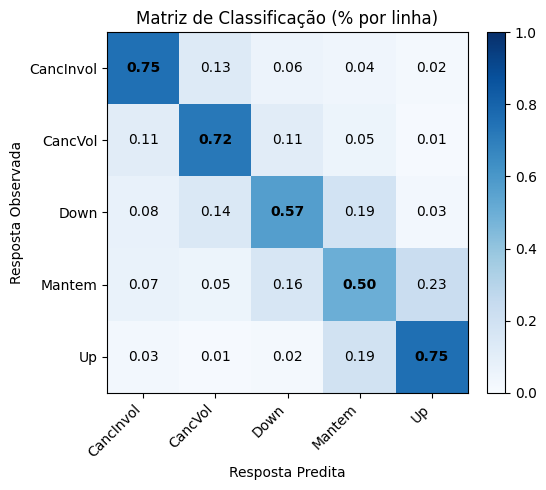

In [42]:
# Gráfico de calor com frequências relativas, somando 100% em cada linha
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(tabela_relativa_linhas.values, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(tabela_relativa_linhas.shape[1]))
ax.set_yticks(range(tabela_relativa_linhas.shape[0]))
ax.set_xticklabels(tabela_relativa_linhas.columns, rotation=45, ha='right')
ax.set_yticklabels(tabela_relativa_linhas.index)
ax.set_xlabel("Resposta Predita"); ax.set_ylabel("Resposta Observada")
ax.set_title("Matriz de Classificação (% por linha)")

for (i, j), v in np.ndenumerate(tabela_relativa_linhas.values):
    same_label = tabela_relativa_linhas.index[i] == tabela_relativa_linhas.columns[j]
    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
            fontweight=("bold" if same_label else "normal"))

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

In [43]:
# Tabela de classificação com frequências relativas, somando 100% em cada coluna
tabela_relativa_colunas = (tabela.div(tabela.sum(axis=0), axis=1)).round(3)
tabela_relativa_colunas

,CancInvol,CancVol,Down,Mantem,Up
CancInvol,0.428,0.089,0.019,0.007,0.005
CancVol,0.042,0.333,0.025,0.006,0.001
Down,0.072,0.167,0.328,0.049,0.010
Mantem,0.427,0.395,0.611,0.875,0.598
Up,0.032,0.016,0.016,0.064,0.386


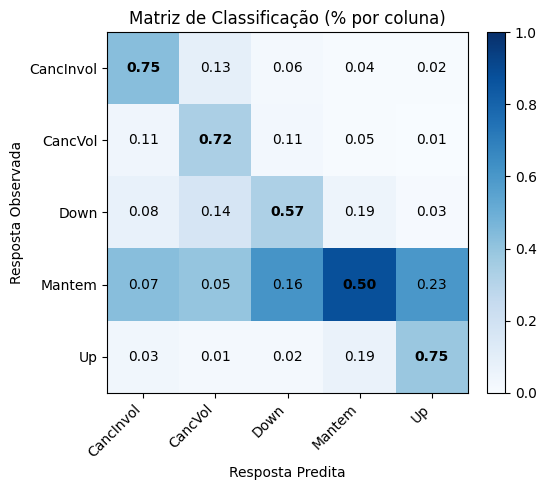

In [44]:
# Gráfico de calor com frequências relativas, somando 100% em cada coluna
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(tabela_relativa_colunas.values, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(tabela_relativa_colunas.shape[1]))
ax.set_yticks(range(tabela_relativa_colunas.shape[0]))
ax.set_xticklabels(tabela_relativa_colunas.columns, rotation=45, ha='right')
ax.set_yticklabels(tabela_relativa_colunas.index)
ax.set_xlabel("Resposta Predita"); ax.set_ylabel("Resposta Observada")
ax.set_title("Matriz de Classificação (% por coluna)")

for (i, j), v in np.ndenumerate(tabela_relativa_linhas.values):
    same_label = tabela_relativa_linhas.index[i] == tabela_relativa_linhas.columns[j]
    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
            fontweight=("bold" if same_label else "normal"))

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

*Desempenho: taxas de acerto por categoria, precisões por categoria, AUC-OVR, acurácia e acurácia balanceada*

In [45]:
# Taxas de acerto por categoria (recalls)
pd.Series(
    np.diag(tabela_relativa_linhas.reindex(columns=tabela_relativa_linhas.index).to_numpy()),
    index=tabela_relativa_linhas.index
)

CancInvol   0.752
CancVol     0.719
Down        0.568
Mantem      0.497
Up          0.754
dtype: float64

In [46]:
# Precisões por categoria
pd.Series(
    np.diag(tabela_relativa_colunas.reindex(columns=tabela_relativa_colunas.index).to_numpy()),
    index=tabela_relativa_colunas.index
)

CancInvol   0.428
CancVol     0.333
Down        0.328
Mantem      0.875
Up          0.386
dtype: float64

In [47]:
# AUC-OVR, acurácia e acurácia balanceada
auc_ovr = roc_auc_score(y_teste, p_hat_teste, multi_class='ovr', average='macro')
acuracia = accuracy_score(y_teste, y_hat_teste)
acuracia_balanceada = balanced_accuracy_score(y_teste, y_hat_teste)

print(f'AUC-OVR: {auc_ovr:.3f}')
print(f'Acurácia: {acuracia:.3f}')
print(f'Acurácia balanceada: {acuracia_balanceada:.3f}')

AUC-OVR: 0.890
Acurácia: 0.562
Acurácia balanceada: 0.658


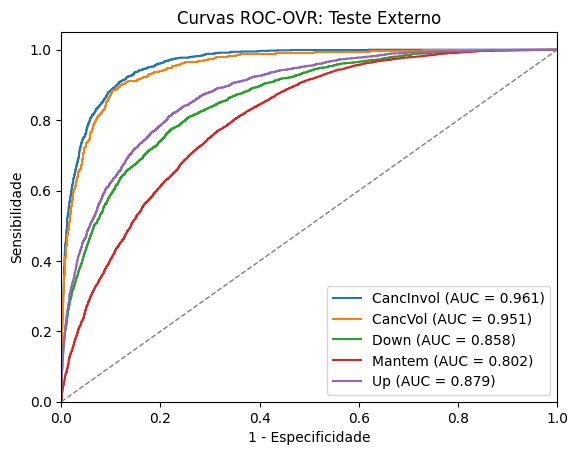

In [48]:
# Exibição das curvas ROC-OVR
plt.figure()
for k, cls in enumerate(classes):
    y_bin = (y_teste == cls).astype(int)
    fpr, tpr, _ = roc_curve(y_bin, p_hat_teste[:, k])
    auc_k = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=1.5, label=f'{ordem_categorias[cls]} (AUC = {auc_k:.3f})')

plt.plot([0, 1], [0, 1], '--', color='gray', lw=1)
plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
plt.xlabel('1 - Especificidade'); plt.ylabel('Sensibilidade')
plt.title('Curvas ROC-OVR: Teste Externo')
plt.legend(loc="lower right")
plt.show()

### **Etapa 9: Interpretabilidade do modelo final**

*Cálculo da importância em redução de impureza para cada variável no modelo final (aplicável apenas para modelos baseados em árvores)*

In [49]:
# ATENÇÃO! Aplicável apenas caso o modelo final seja baseado em árvores, com exceção do gradient boosting com histogramas; caso contrário, resultará em erro
importancias_impureza = pd.Series(modelo_final.feature_importances_,
                                  index=X_treino_tratada.columns).sort_values()

*Gráfico de importâncias em redução de impureza (aplicável apenas para modelos baseados em árvores)*

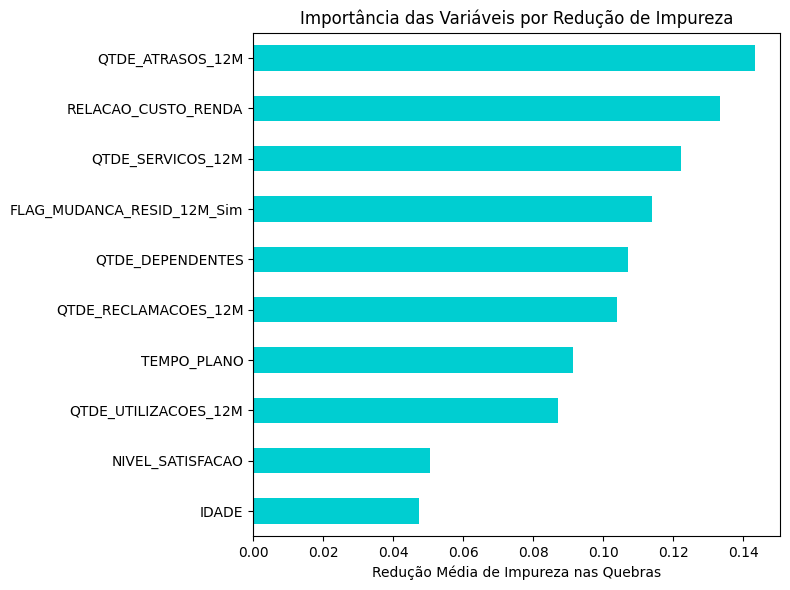

In [50]:
# ATENÇÃO! Aplicável apenas caso o modelo final seja baseado em árvores, com exceção do gradient boosting com histogramas; caso contrário, resultará em erro
plt.figure(figsize=(8, 6))
importancias_impureza.plot.barh(title="Importância das Variáveis por Redução de Impureza",
                                color="darkturquoise")
plt.xlabel("Redução Média de Impureza nas Quebras")
plt.tight_layout()
plt.show()

*Cálculo da importância por permutação para cada variável no modelo final*

In [51]:
importancias_permutacao = permutation_importance(modelo_final,
                                                 X_treino_tratada,
                                                 y_treino,
                                                 n_repeats=30,
                                                 random_state=123, 
                                                 scoring='roc_auc_ovr')
importancias_permutacao = pd.Series(importancias_permutacao.importances_mean,
                                    index=X_treino_tratada.columns).sort_values()

*Gráfico de importâncias por permutação*

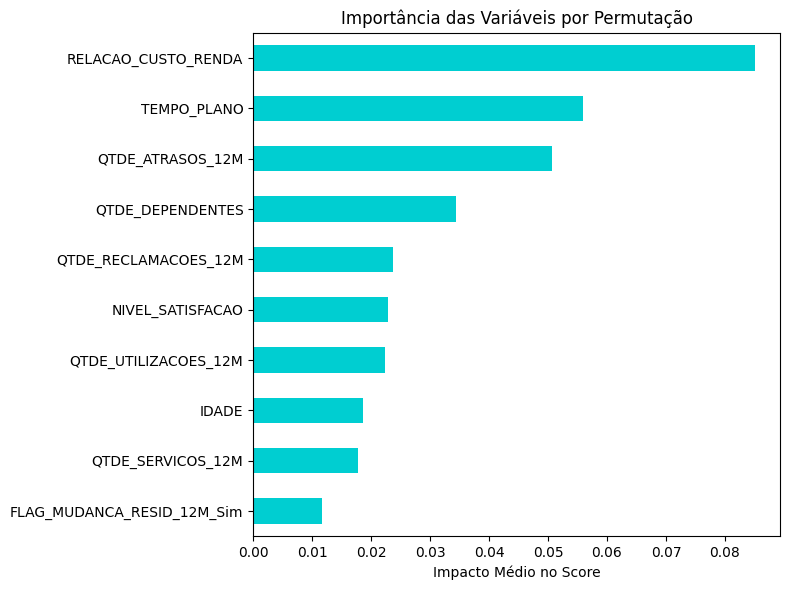

In [52]:
plt.figure(figsize=(8, 6))
importancias_permutacao.plot.barh(title="Importância das Variáveis por Permutação",
                                  color="darkturquoise")
plt.xlabel("Impacto Médio no Score")
plt.tight_layout()
plt.show()

*Cálculo dos valores SHAP das variáveis no modelo final*

In [53]:
if nome_algoritmo not in ['ADABOOST', 'GRADIENT BOOSTING', 'GRADIENT BOOSTING COM HISTOGRAMAS']:
    # Caso demore para rodar, especialmente em bases grandes, substitua X_treino_tratada.shape[0] por um número de tamanho de subamostra (ex.: 100)
    X_amostra = shap.sample(X_treino_tratada, X_treino_tratada.shape[0], random_state=123)
    explainer = shap.Explainer(modelo_final, X_amostra)
    valores_shap = explainer(X_amostra)
else:
    # Para AdaBoost, GB e GB com histogramas, a implementação do cálculo de valores SHAP no caso multinomial não é direta; é preciso usar um método mais oneroso computacionalmente, em uma subamostra pequena de observações
    X_amostra = shap.sample(X_treino_tratada, 100, random_state=123)
    explainer = shap.Explainer(modelo_final.predict_proba, X_amostra)
    valores_shap = explainer(X_amostra)

# Obs. Caso haja algum erro de atividade ("additivity"), acrescente o seguinte argumento na função 'explainer': check_additivity=False

100%|===================| 49990/50000 [43:54<00:00]        

*Gráfico de valores absolutos médios de SHAP*

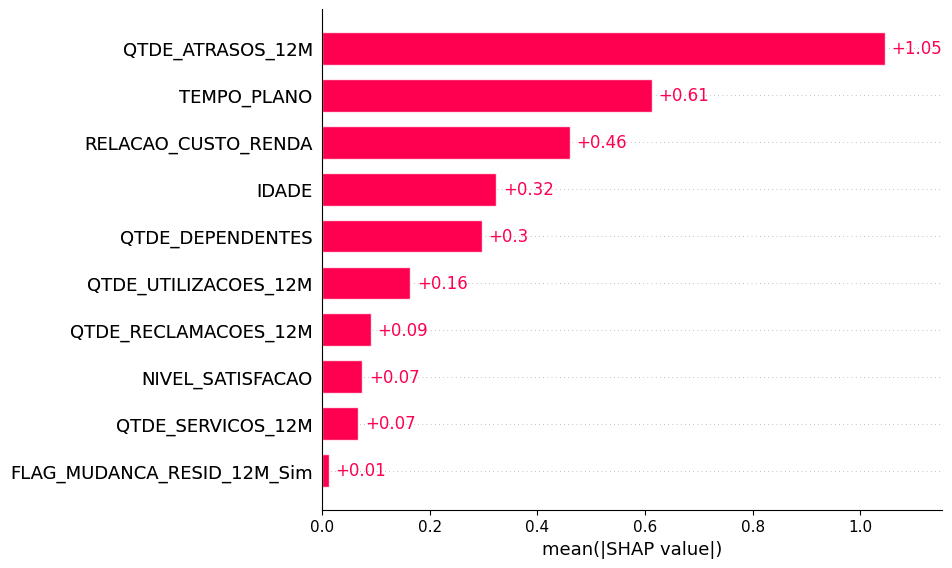

In [54]:
shap.plots.bar(valores_shap[:,:,0])    # ATENÇÃO: Altere o último valor dentro dos colchetes (0, 1, 2, ...) para alternar entras as diferentes categorias de resposta

*Gráfico de direção do impacto baseado em SHAP (beeswarm)*

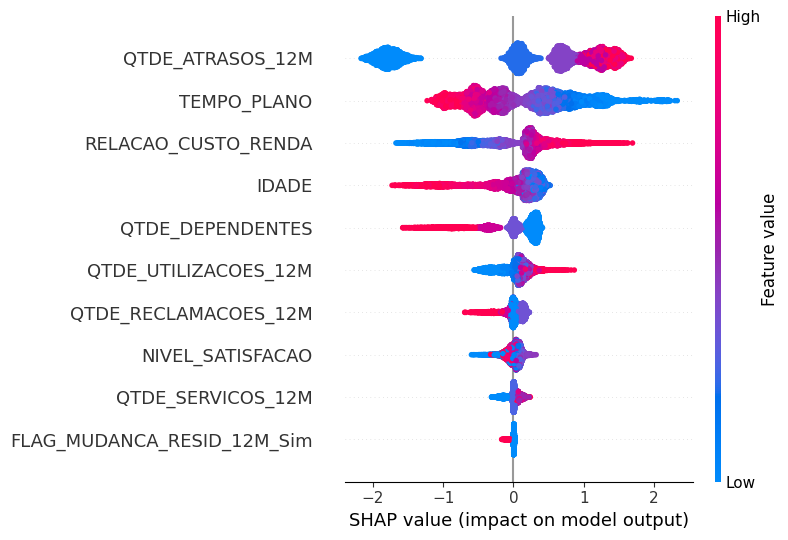

In [55]:
shap.summary_plot(valores_shap[:,:,0], max_display=10)    # ATENÇÃO: Altere o último valor dentro dos colchetes (0, 1, 2, ...) para alternar entras as diferentes categorias de resposta